# Presentasi UAS Machine Learning: Prediksi Risiko Stroke pada Seluruh Data Biomarker Klinis (37.940 Pasien Bersih)

**Mata Kuliah:** Machine Learning (Kelas C)  
**Dosen Pengampu:** Bapak I Ketut Adi Purnawan, S.T., M.Kom.  

**Kelompok 3:**
- Deliana Br Manalu (2305551036)
- Ravi Arnan Irianto (2305551076)
- Ezza Putra Wibawa (2305551144)
- Devin (2305551173)

---

## Peta Alur Proses di Notebook (End-to-End Colab Pipeline)

Notebook ini disusun sebagai **kode presentasi utama UAS** yang berjalan penuh dari awal sampai akhir di Google Colab:
1. **Pemuatan & Audit Data Mentah (50.000 baris, 40 kolom)**: Mengecek tipe data, nilai kosong (*missing values*), duplikasi penuh maupun duplikasi tanpa `Patient_ID`, serta distribusi kelas.
2. **Pembersihan Data & Pencegahan Kebocoran Target**: Menghilangkan seluruh baris yang memiliki nilai kosong (`dropna`) dan duplikasi (`drop_duplicates`) sehingga tersisa **37.940 pasien bersih** (menggunakan seluruh baris valid tanpa pemotongan sampel), serta membuang kolom *target leakage*.
3. **EDA Terarah (Konteks Klinis)**: Menganalisis pola fitur klinis kunci (usia, tekanan darah sistolik, glukosa, HbA1c, riwayat TIA) terhadap risiko stroke tinggi.
4. **Pembagian Data Stratified (70% Latih / 15% Validasi / 15% Uji)**: Memastikan proporsi kelas konsisten dan menjaga data uji benar-benar terisolasi.
5. **Preprocessing Berbeda Sesuai Karakteristik Model**:
   - **Logistic Regression**: `StandardScaler` untuk fitur numerik + `OneHotEncoder(drop='first')` untuk kategorikal.
   - **Random Forest**: Skala numerik asli (`passthrough`, tanpa scaling) + `OrdinalEncoder` untuk kategorikal.
   - **Gradient Boosting**: Skala numerik asli (`passthrough`, tanpa scaling) + `OneHotEncoder` untuk kategorikal.
6. **Evaluasi Baseline vs Improvement + Confusion Matrix per Model**:
   - **Baseline**: Parameter default scikit-learn pada ambang standar `t = 0,50`.
   - **Improvement**: Penyetelan hyperparameter spesifik model, penyeimbangan bobot kelas (pada Random Forest), *Threshold Tuning* pada data validasi, serta penggabungan **Ensemble Soft Voting**.
   - Setiap model dilengkapi grafik **Confusion Matrix Baseline vs Improvement**, **Kurva ROC**, dan **Kurva Precision-Recall**.
7. **Validasi Berlapis**:
   - **5-Fold Stratified Cross-Validation** (mean +/- std).
   - **Bootstrap 95% Confidence Interval** (1.000 iterasi pada Test Set).
   - **Learning Curve** (deteksi overfitting/underfitting).
   - **Validasi Klinis (Feature Importance & Koefisien Log-Odds)**.

## 1. Persiapan Lingkungan & Pustaka

In [1]:
import json
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    GradientBoostingClassifier,
    RandomForestClassifier,
    VotingClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    learning_curve,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

warnings.filterwarnings("ignore")

plt.style.use(
    "seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default"
)
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["font.size"] = 10
plt.rcParams["figure.dpi"] = 120

SEED = 42
np.random.seed(SEED)

# Direktori output lokal (otomatis dibuat jika dijalankan di Colab maupun lokal)
ASSET_DIR = Path("assets/evaluasi_15")
if Path("..").resolve().name == "machine-learning" or Path("../datasets").exists():
    ASSET_DIR = Path("../assets/evaluasi_15")
ASSET_DIR.mkdir(parents=True, exist_ok=True)

ARTIFACT_DIR = Path("artifacts")
if Path("../artifacts").exists():
    ARTIFACT_DIR = Path("../artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

print("Pustaka siap. Direktori aset:", ASSET_DIR.resolve())

Pustaka siap. Direktori aset: /home/ravi/Projects/machine-learning/assets/evaluasi_15


## 2. Pemuatan Seluruh Dataset & Analisis Kualitas Data (Missing Value & Duplikasi)

Dataset yang digunakan adalah `stroke_risk_prediction_dataset.csv` yang memuat **50.000 catatan pasien dan 40 atribut** (demografi, gaya hidup, biomarker laboratorium seperti tekanan darah sistolik/diastolik, HbA1c, profil lipid kolesterol, serta riwayat klinis TIA dan fibrilasi atrium).

Sesuai arahan evaluasi, kita memeriksa dan menampilkan kondisi seluruh baris mentah terlebih dahulu sebelum pembersihan:
1. Menghitung jumlah data kosong (*missing values*) per kolom dan persentase baris yang terdampak.
2. Mengecek duplikasi baris penuh, duplikasi `Patient_ID`, maupun duplikasi kombinasi fitur tanpa `Patient_ID`.

In [2]:
GITHUB_RAW_URL = (
    "https://raw.githubusercontent.com/ravi-arman/machine-learning/main/"
    "datasets/stroke_risk_prediction_dataset.csv"
)

candidate_paths = [
    Path("datasets/stroke_risk_prediction_dataset.csv"),
    Path("../datasets/stroke_risk_prediction_dataset.csv"),
    Path("stroke_risk_prediction_dataset.csv"),
]

data_path = next((p for p in candidate_paths if p.exists()), None)

if data_path is not None:
    print(f"Memuat dataset lokal dari: {data_path.resolve()}")
    df_raw = pd.read_csv(data_path)
else:
    print(f"File lokal tidak ditemukan, mengunduh dari GitHub:\n{GITHUB_RAW_URL}")
    df_raw = pd.read_csv(GITHUB_RAW_URL)

print(f"\nDimensi Dataset Mentah: {df_raw.shape[0]:,} baris x {df_raw.shape[1]} kolom")
display(df_raw.head(5))
print("\nStatistik Deskriptif Atribut Numerik (Data Mentah):")
display(df_raw.select_dtypes(include=["number"]).drop(columns=["Patient_ID"]).describe().T[["count", "mean", "std", "min", "50%", "max"]].round(2))

Memuat dataset lokal dari: /home/ravi/Projects/machine-learning/datasets/stroke_risk_prediction_dataset.csv

Dimensi Dataset Mentah: 50,000 baris x 40 kolom


,Patient_ID,Age,Gender,Country,Height_cm,Weight_kg,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Heart_Rate,...,Medication_Adherence,Exercise_Hours_Per_Week,Daily_Walking_Minutes,Work_Type,Residence_Type,Air_Pollution_Exposure,Stroke_Risk_Score,AI_Health_Recommendation,Doctor_Consultation_Needed,Stroke_Risk
0,1,80.0,Male,China,145.2,69.3,32.9,112,82,109,...,Excellent,NaN,79.0,Retired,Urban,High,47,Exercise Regularly,Yes,Moderate
1,2,37.0,Female,United Kingdom,188.6,110.8,31.1,137,76,59,...,Average,0.6,48.0,Student,Rural,Medium,40,Improve Diet Quality,Yes,Moderate
2,3,85.0,Female,Germany,175.5,103.7,33.7,108,105,89,...,Poor,1.7,114.0,Private,Rural,Medium,76,Monitor Blood Glucose Daily,Yes,High
3,4,44.0,Other,Brazil,161.3,50.2,19.3,126,73,88,...,Poor,1.5,101.0,Retired,Rural,Low,40,Exercise Regularly,Yes,Moderate
4,5,52.0,Female,United States,162.8,103.6,39.1,115,60,70,...,Average,7.1,55.0,Government,Rural,Medium,38,Monitor Blood Pressure,Yes,Moderate



Statistik Deskriptif Atribut Numerik (Data Mentah):


,count,mean,std,min,50%,max
Age,49781.0,53.90,21.07,18.0,54.0,90.0
Height_cm,48475.0,170.13,14.48,145.0,170.1,195.0
Weight_kg,48477.0,87.51,24.57,45.0,87.5,130.0
BMI,50000.0,30.90,10.25,11.9,30.1,61.5
Blood_Pressure_Systolic,50000.0,135.06,20.53,100.0,135.0,170.0
Blood_Pressure_Diastolic,50000.0,84.84,14.69,60.0,85.0,110.0
Heart_Rate,50000.0,82.52,16.14,55.0,83.0,110.0
Blood_Glucose,49040.0,145.03,43.41,70.0,145.1,220.0
HbA1c,48994.0,7.49,1.73,4.5,7.5,10.5
Total_Cholesterol,48996.0,225.02,54.78,130.0,224.9,320.0


In [3]:
# Audit Missing Values & Duplikasi pada Seluruh 50.000 Baris
na_per_col = df_raw.isna().sum()
na_df = pd.DataFrame({
    "Kolom": na_per_col.index,
    "Jumlah_Kosong": na_per_col.values,
    "Persentase (%)": (na_per_col.values / len(df_raw)) * 100,
})
na_nonzero = na_df[na_df["Jumlah_Kosong"] > 0].sort_values("Jumlah_Kosong", ascending=False)

rows_with_na = int(df_raw.isna().any(axis=1).sum())
dup_exact = int(df_raw.duplicated().sum())
dup_id = int(df_raw["Patient_ID"].duplicated().sum())
dup_features = int(df_raw.drop(columns=["Patient_ID"]).duplicated().sum())

print("=== RINGKASAN AUDIT KUALITAS DATA MENTAH ===")
print(f"Total baris awal                : {len(df_raw):,}")
print(f"Total sel kosong                : {int(df_raw.isna().sum().sum()):,} sel pada {len(na_nonzero)} kolom")
print(f"Baris yang memiliki data kosong : {rows_with_na:,} baris ({rows_with_na / len(df_raw) * 100:.2f}%)")
print(f"Duplikasi baris penuh           : {dup_exact:,}")
print(f"Duplikasi Patient_ID            : {dup_id:,}")
print(f"Duplikasi fitur (tanpa ID)      : {dup_features:,}")
print("\nRincian Kolom dengan Missing Values:")
display(na_nonzero.reset_index(drop=True))

=== RINGKASAN AUDIT KUALITAS DATA MENTAH ===
Total baris awal                : 50,000
Total sel kosong                : 13,522 sel pada 13 kolom
Baris yang memiliki data kosong : 12,060 baris (24.12%)
Duplikasi baris penuh           : 0
Duplikasi Patient_ID            : 0
Duplikasi fitur (tanpa ID)      : 0

Rincian Kolom dengan Missing Values:


,Kolom,Jumlah_Kosong,Persentase (%)
0,Height_cm,1525,3.050
1,Weight_kg,1523,3.046
2,Exercise_Hours_Per_Week,1054,2.108
3,Medication_Adherence,1051,2.102
4,Daily_Walking_Minutes,1051,2.102
5,LDL,1050,2.100
6,Triglycerides,1032,2.064
7,Sleep_Hours,1026,2.052
8,HDL,1021,2.042
9,HbA1c,1006,2.012


## 3. Pembersihan Data (`dropna` & `drop_duplicates`) dan Eliminasi *Target Leakage*

Langkah pembersihan yang dilakukan:
1. **Menghilangkan Baris dengan Data Kosong (`dropna`)**: Sebanyak 12.060 baris yang memiliki minimal satu nilai kosong dihapus agar seluruh data yang masuk ke model merupakan pengukuran klinis asli tanpa nilai imputasi buatan.
2. **Menghilangkan Baris Duplikat (`drop_duplicates`)**: Memastikan tidak ada baris identik yang masuk ke data latih maupun data uji (mencegah kebocoran antar-split).
3. **Eliminasi Kolom *Target Leakage***: Membuang `Patient_ID`, `Stroke_Risk_Score`, `AI_Health_Recommendation`, dan `Doctor_Consultation_Needed` karena kolom tersebut merupakan skor turunan atau rekomendasi pasca-diagnosis.
4. **Formulasi Target Biner**: `stroke_risk_high = 1` untuk kategori `High` dan `0` untuk kategori `Moderate`/`Low`.

=== HASIL PEMBERSIHAN DATA ===
Baris awal                     : 50,000
Baris setelah dropna()         : 37,940 (dibuang 12,060)
Baris setelah drop_duplicates(): 37,940 (dibuang 0)
Duplikasi fitur tanpa ID       : 0
Sisa missing value             : 0
Fitur prediktor valid          : 35 kolom (16 numerik, 19 kategorikal)
Distribusi Target (0 vs 1)     : 28,747 Non-High (75,77%) | 9,193 High Risk (24.23%)


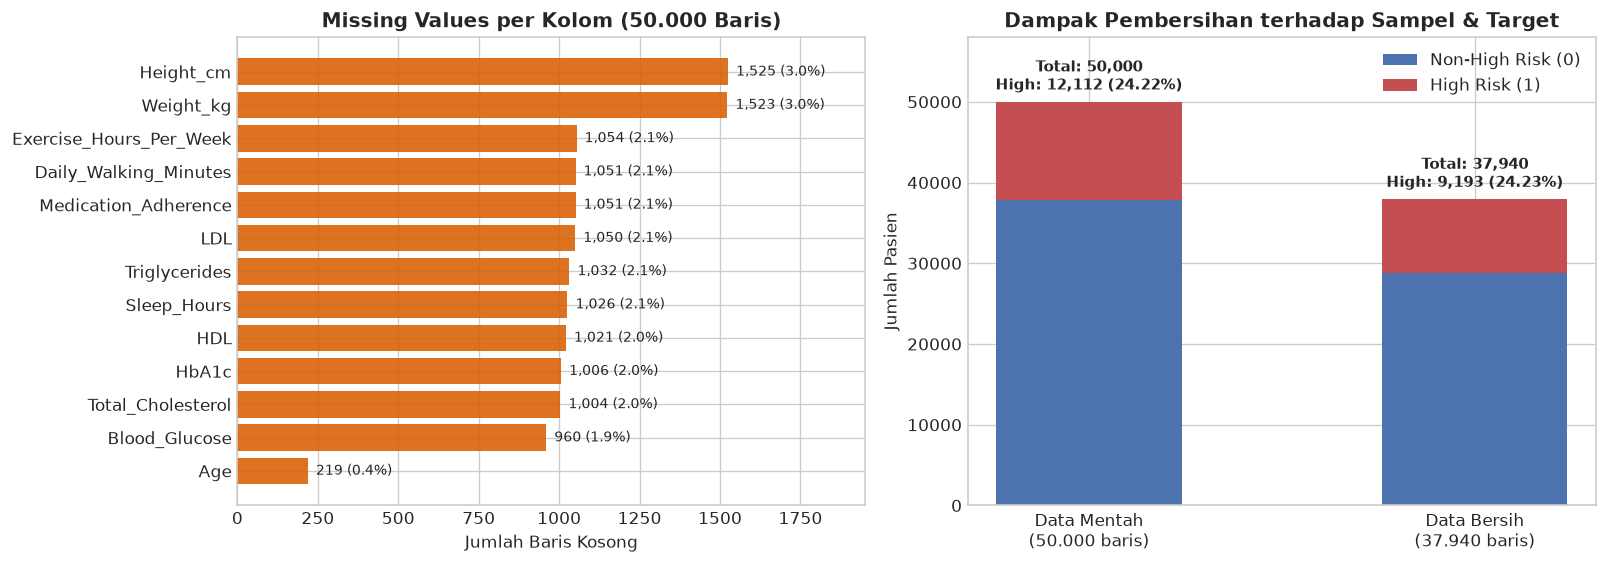

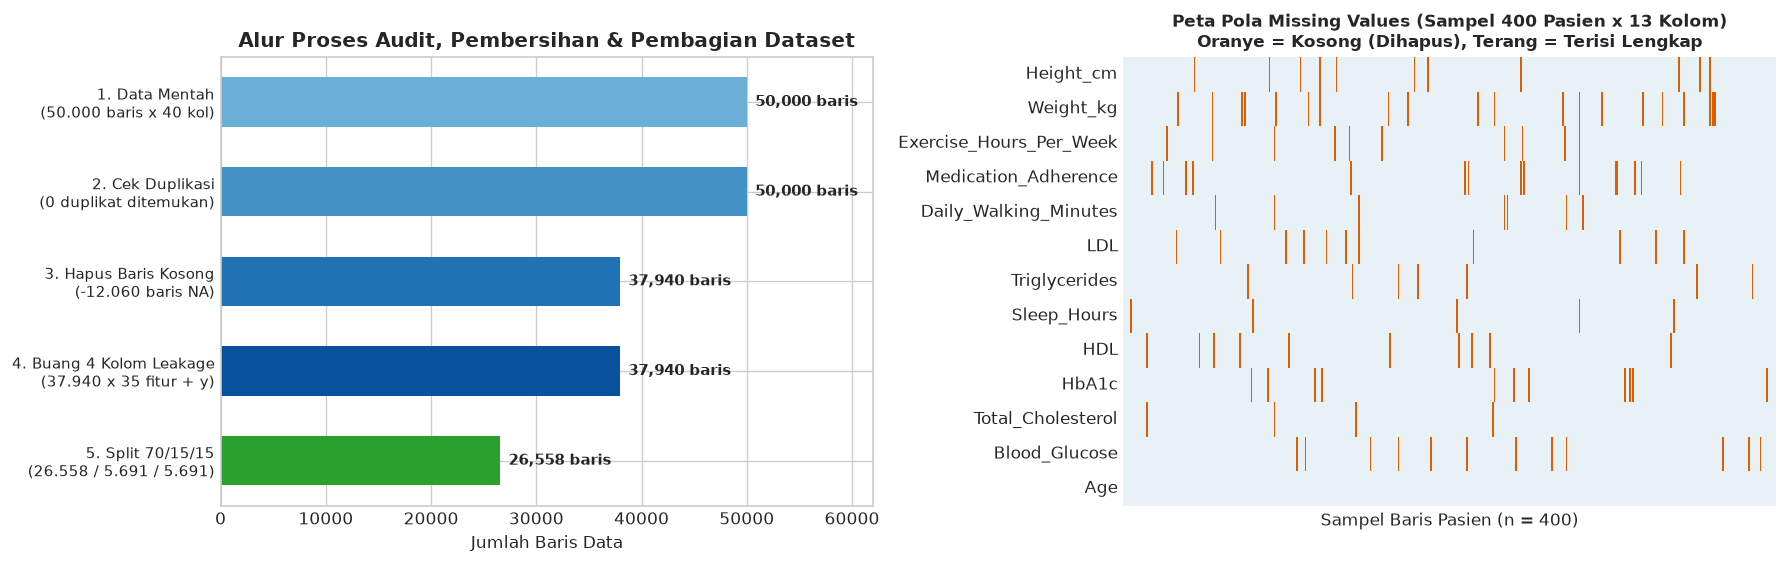

Contoh 5 Baris Data Bersih (35 Fitur Prediktor Siap Preprocessing):


,Age,Gender,Country,Height_cm,Weight_kg,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Heart_Rate,Blood_Glucose,...,Heart_Disease,Previous_TIA,Atrial_Fibrillation,Chronic_Kidney_Disease,Medication_Adherence,Exercise_Hours_Per_Week,Daily_Walking_Minutes,Work_Type,Residence_Type,Air_Pollution_Exposure
0,85.0,Female,Germany,175.5,103.7,33.7,108,105,89,196.4,...,No,No,No,No,Poor,1.7,114.0,Private,Rural,Medium
1,44.0,Other,Brazil,161.3,50.2,19.3,126,73,88,209.1,...,No,No,No,Yes,Poor,1.5,101.0,Retired,Rural,Low
2,52.0,Female,United States,162.8,103.6,39.1,115,60,70,88.6,...,No,No,No,No,Average,7.1,55.0,Government,Rural,Medium
3,80.0,Other,United Kingdom,163.9,87.8,32.7,164,82,98,155.7,...,No,No,Yes,No,Average,6.3,47.0,Private,Urban,Medium
4,33.0,Female,Singapore,166.2,58.8,21.3,149,88,86,145.0,...,No,No,No,No,Excellent,2.2,5.0,Student,Urban,Low


In [4]:
# 1. Hapus baris dengan missing value dan duplikasi
df_no_na = df_raw.dropna().copy()
after_na = len(df_no_na)
df_clean = df_no_na.drop_duplicates().reset_index(drop=True)
after_dup = len(df_clean)

# Cek ulang duplikasi fitur tanpa Patient_ID setelah dropna
dup_feat_clean = int(df_clean.drop(columns=["Patient_ID"]).duplicated().sum())

# 2. Formulasi Target & Eliminasi Target Leakage
y = (df_clean["Stroke_Risk"] == "High").astype(int)
leak_cols = [
    "Patient_ID",
    "Stroke_Risk_Score",
    "AI_Health_Recommendation",
    "Doctor_Consultation_Needed",
    "Stroke_Risk",
]
X = df_clean.drop(columns=leak_cols).copy()

num_cols = X.select_dtypes(include=["number"]).columns.tolist()
cat_cols = X.select_dtypes(exclude=["number"]).columns.tolist()

print("=== HASIL PEMBERSIHAN DATA ===")
print(f"Baris awal                     : {len(df_raw):,}")
print(f"Baris setelah dropna()         : {after_na:,} (dibuang {len(df_raw) - after_na:,})")
print(f"Baris setelah drop_duplicates(): {after_dup:,} (dibuang {after_na - after_dup:,})")
print(f"Duplikasi fitur tanpa ID       : {dup_feat_clean}")
print(f"Sisa missing value             : {int(X.isna().sum().sum())}")
print(f"Fitur prediktor valid          : {X.shape[1]} kolom ({len(num_cols)} numerik, {len(cat_cols)} kategorikal)")
print(f"Distribusi Target (0 vs 1)     : {(y == 0).sum():,} Non-High (75,77%) | {(y == 1).sum():,} High Risk ({y.mean()*100:.2f}%)")

# Visualisasi Ringkasan Audit Data & Distribusi Kelas
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

# Panel 1: Missing Values per Kolom
na_plot = na_nonzero.sort_values("Jumlah_Kosong", ascending=True)
axes[0].barh(na_plot["Kolom"], na_plot["Jumlah_Kosong"], color="#d95f02", alpha=0.88)
axes[0].set_title("Missing Values per Kolom (50.000 Baris)", fontweight="bold")
axes[0].set_xlabel("Jumlah Baris Kosong")
for idx, val in enumerate(na_plot["Jumlah_Kosong"]):
    axes[0].text(val + 25, idx, f"{val:,} ({val/len(df_raw)*100:.1f}%)", va="center", fontsize=8.5)
axes[0].set_xlim(0, na_plot["Jumlah_Kosong"].max() * 1.28)

# Panel 2: Perbandingan Jumlah Baris & Distribusi Kelas
labels_stage = ["Data Mentah\n(50.000 baris)", "Data Bersih\n(37.940 baris)"]
high_counts = [int((df_raw["Stroke_Risk"] == "High").sum()), int((y == 1).sum())]
non_high_counts = [len(df_raw) - high_counts[0], len(df_clean) - high_counts[1]]

x_pos = np.arange(len(labels_stage))
axes[1].bar(x_pos, non_high_counts, width=0.48, label="Non-High Risk (0)", color="#4c72b0")
axes[1].bar(x_pos, high_counts, width=0.48, bottom=non_high_counts, label="High Risk (1)", color="#c44e52")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(labels_stage, fontsize=10)
axes[1].set_ylabel("Jumlah Pasien")
axes[1].set_title("Dampak Pembersihan terhadap Sampel & Target", fontweight="bold")
axes[1].legend(loc="upper right")
for i in range(2):
    tot = non_high_counts[i] + high_counts[i]
    axes[1].text(i, tot + 900, f"Total: {tot:,}\nHigh: {high_counts[i]:,} ({high_counts[i]/tot*100:.2f}%)",
                 ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[1].set_ylim(0, 58000)

plt.tight_layout()
plt.savefig(ASSET_DIR / "fig_01_audit_dan_pembersihan.png", dpi=150, bbox_inches="tight")
plt.show()

# Visualisasi Tambahan: Peta Pola Missing Values & Alur Proses Pembersihan Data
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

# Panel Kiri: Diagram Alur Proses Data (50.000 -> 37.940 -> Split)
steps_label = [
    "1. Data Mentah\n(50.000 baris x 40 kol)",
    "2. Cek Duplikasi\n(0 duplikat ditemukan)",
    "3. Hapus Baris Kosong\n(-12.060 baris NA)",
    "4. Buang 4 Kolom Leakage\n(37.940 x 35 fitur + y)",
    "5. Split 70/15/15\n(26.558 / 5.691 / 5.691)",
]
steps_vals = [50000, 50000, 37940, 37940, 26558]
step_colors = ["#6baed6", "#4292c6", "#2171b5", "#08519c", "#2ca02c"]
y_pos_s = np.arange(len(steps_label))[::-1]
bars_s = axes[0].barh(y_pos_s, steps_vals, color=step_colors, height=0.55)
axes[0].set_yticks(y_pos_s)
axes[0].set_yticklabels(steps_label, fontsize=9)
axes[0].set_xlabel("Jumlah Baris Data")
axes[0].set_title("Alur Proses Audit, Pembersihan & Pembagian Dataset", fontweight="bold")
axes[0].set_xlim(0, 62000)
for b, v in zip(bars_s, steps_vals):
    axes[0].text(v + 800, b.get_y() + b.get_height()/2, f"{v:,} baris", va="center", fontsize=9, fontweight="bold")

# Panel Kanan: Heatmap Pola Missing Value pada 500 Sampel Baris Mentah
na_cols_list = na_nonzero["Kolom"].tolist()
sample_na = df_raw[na_cols_list].sample(n=400, random_state=SEED).isna().astype(int).T
sns.heatmap(
    sample_na, cmap=["#e8f1f5", "#d95f02"], cbar=False, ax=axes[1],
    xticklabels=False, yticklabels=na_cols_list
)
axes[1].set_title("Peta Pola Missing Values (Sampel 400 Pasien x 13 Kolom)\nOranye = Kosong (Dihapus), Terang = Terisi Lengkap", fontweight="bold", fontsize=10)
axes[1].set_xlabel("Sampel Baris Pasien (n = 400)")

plt.tight_layout()
plt.savefig(ASSET_DIR / "fig_01b_alur_proses_dan_missing_map.png", dpi=150, bbox_inches="tight")
plt.show()

print("Contoh 5 Baris Data Bersih (35 Fitur Prediktor Siap Preprocessing):")
display(X.head(5))

## 4. Eksplorasi Data Klinis Terarah (EDA Singkat Sebelum Pemodelan)

Sebagai konteks sebelum masuk ke rekayasa fitur dan pemodelan, grafik di bawah menunjukkan bagaimana profil biomarker utama (Usia, Tekanan Darah Sistolik, Kadar Glukosa Darah, HbA1c, serta riwayat TIA/Fibrilasi Atrium) membedakan pasien `High Risk` dari `Non-High Risk` pada 37.940 pasien bersih.

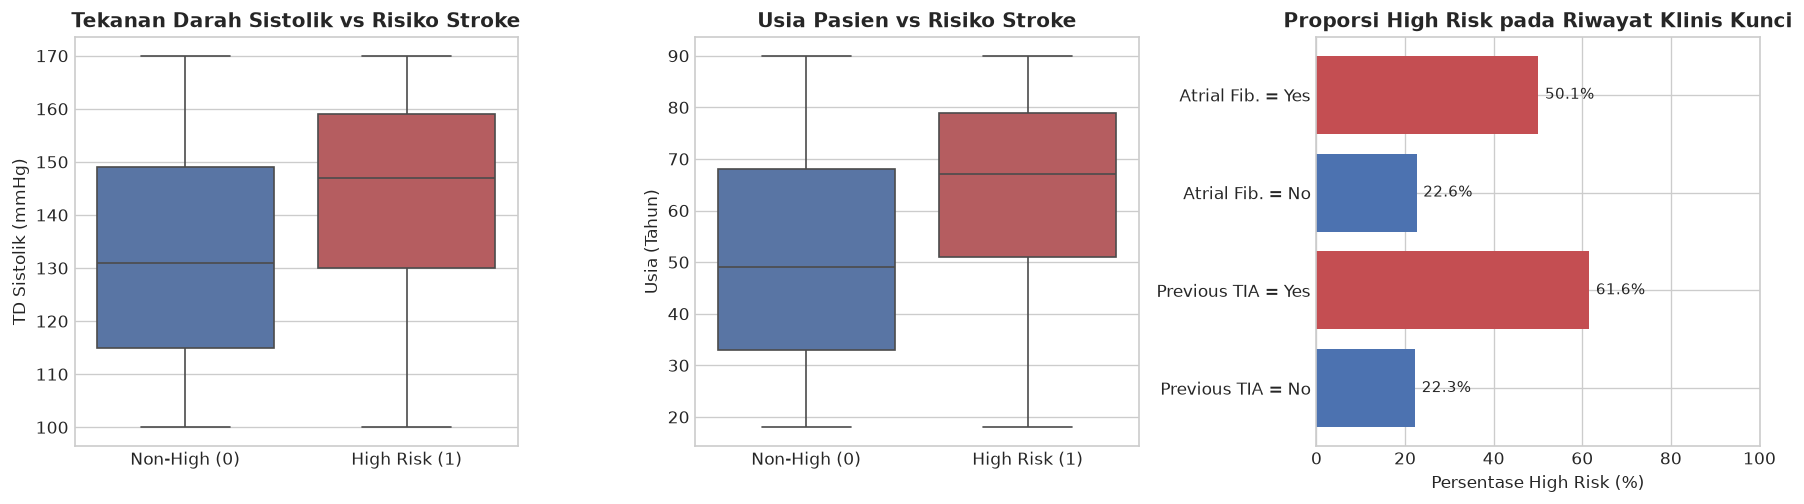

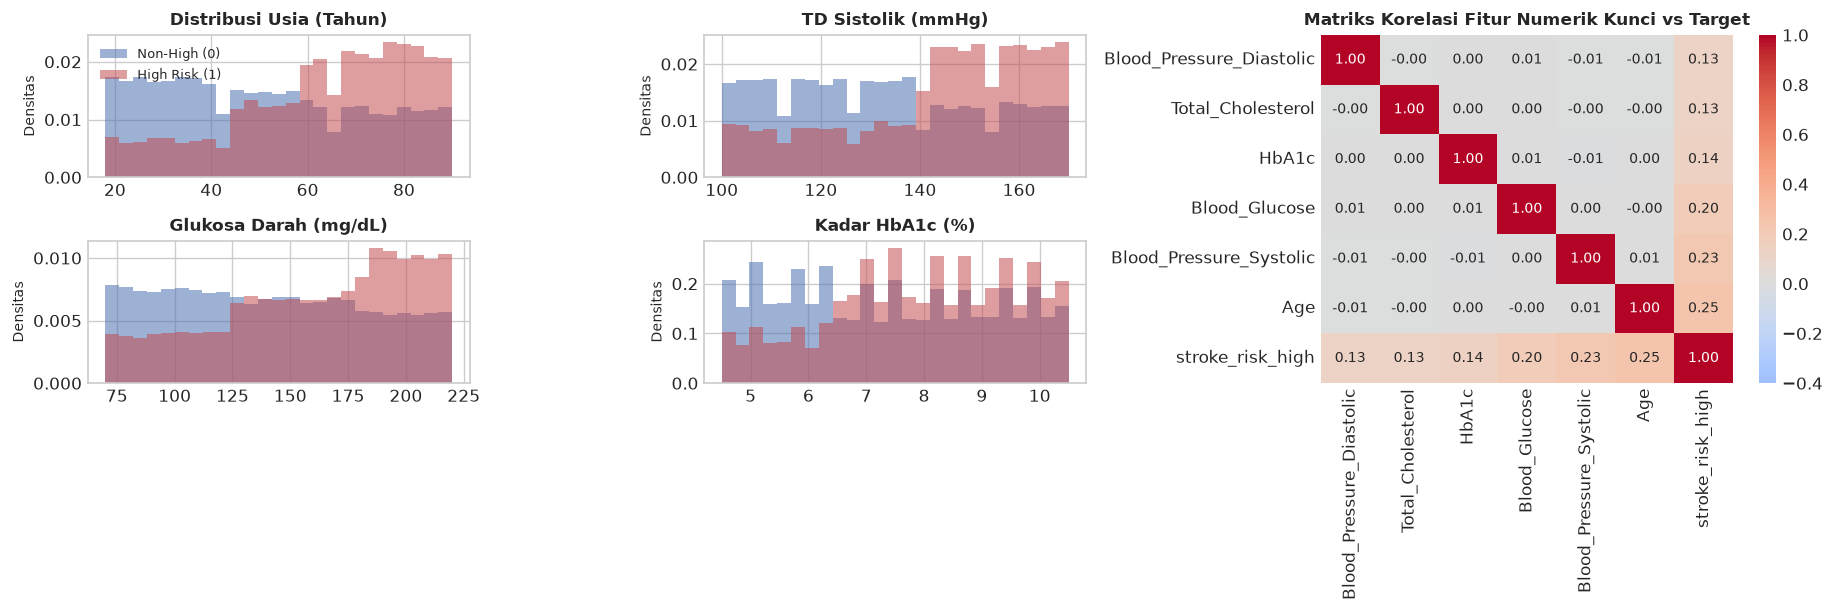

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

plot_df = X[["Age", "Blood_Pressure_Systolic", "Blood_Glucose", "Previous_TIA", "Atrial_Fibrillation"]].copy()
plot_df["Risk_Label"] = np.where(y == 1, "High Risk (1)", "Non-High (0)")

# 1. Boxplot TD Sistolik
sns.boxplot(data=plot_df, x="Risk_Label", y="Blood_Pressure_Systolic", order=["Non-High (0)", "High Risk (1)"], palette=["#4c72b0", "#c44e52"], ax=axes[0])
axes[0].set_title("Tekanan Darah Sistolik vs Risiko Stroke", fontweight="bold")
axes[0].set_xlabel("")
axes[0].set_ylabel("TD Sistolik (mmHg)")

# 2. Boxplot Usia
sns.boxplot(data=plot_df, x="Risk_Label", y="Age", order=["Non-High (0)", "High Risk (1)"], palette=["#4c72b0", "#c44e52"], ax=axes[1])
axes[1].set_title("Usia Pasien vs Risiko Stroke", fontweight="bold")
axes[1].set_xlabel("")
axes[1].set_ylabel("Usia (Tahun)")

# 3. Tingkat High Risk berdasarkan Riwayat TIA & AFib
risk_rates = pd.DataFrame({
    "Faktor Klinis": ["Previous TIA = No", "Previous TIA = Yes", "Atrial Fib. = No", "Atrial Fib. = Yes"],
    "Proporsi High Risk (%)": [
        y[X["Previous_TIA"] == "No"].mean() * 100,
        y[X["Previous_TIA"] == "Yes"].mean() * 100,
        y[X["Atrial_Fibrillation"] == "No"].mean() * 100,
        y[X["Atrial_Fibrillation"] == "Yes"].mean() * 100,
    ],
})
colors_bar = ["#4c72b0", "#c44e52", "#4c72b0", "#c44e52"]
bars = axes[2].barh(risk_rates["Faktor Klinis"], risk_rates["Proporsi High Risk (%)"], color=colors_bar)
axes[2].set_title("Proporsi High Risk pada Riwayat Klinis Kunci", fontweight="bold")
axes[2].set_xlabel("Persentase High Risk (%)")
axes[2].set_xlim(0, 100)
for b in bars:
    w = b.get_width()
    axes[2].text(w + 1.5, b.get_y() + b.get_height()/2, f"{w:.1f}%", va="center", fontsize=9)

plt.tight_layout()
plt.savefig(ASSET_DIR / "fig_02_eda_klinis.png", dpi=150, bbox_inches="tight")
plt.show()

# Visualisasi Tambahan EDA: Distribusi Biomarker Utama & Korelasi Fitur ke Target
fig = plt.figure(figsize=(15.5, 5.2))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 1.35])

dist_feats = [
    ("Age", "Distribusi Usia (Tahun)"),
    ("Blood_Pressure_Systolic", "TD Sistolik (mmHg)"),
    ("Blood_Glucose", "Glukosa Darah (mg/dL)"),
    ("HbA1c", "Kadar HbA1c (%)"),
]
for i, (col_f, ttl_f) in enumerate(dist_feats):
    ax_d = fig.add_subplot(gs[i // 2, i % 2])
    ax_d.hist(X.loc[y == 0, col_f], bins=25, density=True, alpha=0.55, color="#4c72b0", label="Non-High (0)")
    ax_d.hist(X.loc[y == 1, col_f], bins=25, density=True, alpha=0.55, color="#c44e52", label="High Risk (1)")
    ax_d.set_title(ttl_f, fontweight="bold", fontsize=10)
    ax_d.set_ylabel("Densitas", fontsize=8.5)
    if i == 0:
        ax_d.legend(fontsize=8, loc="upper left")

# Panel Kanan: Korelasi Pearson Top Fitur Numerik terhadap Target
ax_corr = fig.add_subplot(gs[:, 2])
corr_df = X[num_cols].copy()
corr_df["stroke_risk_high"] = y
corr_target = corr_df.corr(numeric_only=True)["stroke_risk_high"].drop("stroke_risk_high").sort_values()
top_corr_cols = corr_target.index.tolist()[-6:] + ["stroke_risk_high"]
sns.heatmap(
    corr_df[top_corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm",
    center=0, vmin=-0.4, vmax=1.0, ax=ax_corr, annot_kws={"size": 8.5}
)
ax_corr.set_title("Matriks Korelasi Fitur Numerik Kunci vs Target", fontweight="bold", fontsize=10)

plt.tight_layout()
plt.savefig(ASSET_DIR / "fig_02b_distribusi_dan_korelasi.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Pembagian Data Stratified 70 / 15 / 15 (Anti Data Leakage)

Seluruh **37.940 baris bersih** dibagi secara bertingkat (*stratified*) agar prevalensi `High Risk` (~24,23%) terjaga identik di setiap partisi:
- **70% Data Latih (26.558 baris)**: Digunakan untuk fitting transformasi preprocessing dan pelatihan model.
- **15% Data Validasi (5.691 baris)**: Digunakan untuk pencarian hyperparameter dan kalibrasi ambang keputusan (*threshold tuning*).
- **15% Data Uji (5.691 baris)**: Dikunci sebagai evaluasi akhir independen (*unseen test set*).

In [6]:
X_train, X_rest, y_train, y_rest = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_rest, y_rest, test_size=0.50, stratify=y_rest, random_state=SEED
)

split_summary = pd.DataFrame([
    {"Partisi": "Train (70%)", "Jumlah_Baris": len(X_train), "High_Risk_1": int(y_train.sum()), "Prevalensi (%)": round(y_train.mean()*100, 2)},
    {"Partisi": "Validation (15%)", "Jumlah_Baris": len(X_val), "High_Risk_1": int(y_val.sum()), "Prevalensi (%)": round(y_val.mean()*100, 2)},
    {"Partisi": "Test (15%)", "Jumlah_Baris": len(X_test), "High_Risk_1": int(y_test.sum()), "Prevalensi (%)": round(y_test.mean()*100, 2)},
])
display(split_summary)

,Partisi,Jumlah_Baris,High_Risk_1,Prevalensi (%)
0,Train (70%),26558,6435,24.23
1,Validation (15%),5691,1379,24.23
2,Test (15%),5691,1379,24.23


## 6. Perancangan Pipeline Preprocessing Berbeda Tiap Model

Sesuai prinsip metodologi machine learning, setiap keluarga algoritma membutuhkan perlakuan preprocessing yang berbeda:

| Model Algoritma | Perlakuan Fitur Numerik (16 fitur) | Perlakuan Fitur Kategorikal (19 fitur) | Alasan Teknis |
|---|---|---|---|
| **Logistic Regression** | `StandardScaler()` (mean=0, std=1) | `OneHotEncoder(drop='first')` | Model linear berbasis gradien & penalti L2 sangat sensitif terhadap perbedaan skala satuan (Usia vs Kolesterol vs biner), dan `drop='first'` mencegah multikolinearitas sempurna. |
| **Random Forest** | `passthrough` (tanpa scaling, skala asli) | `OrdinalEncoder` | Algoritma berbasis pohon (*tree-based*) bersifat *scale-invariant* karena pemisahan node hanya bergantung pada urutan nilai, bukan jarak Euclidean. Encoding ordinal menjaga dimensi split tetap ringkas. |
| **Gradient Boosting** | `passthrough` (tanpa scaling, skala asli) | `OneHotEncoder` (tanpa drop) | Boosting sekuensial meminimalkan residu gradien pada setiap kategori secara terpisah; one-hot penuh memudahkan pohon dangkal menangkap efek spesifik tiap kategori. |

Dimensi fitur setelah preprocessing berbeda per model:
  - Logistic Regression (StandardScaler + OHE drop='first') : 69 kolom
  - Random Forest       (Passthrough + OrdinalEncoder)      : 35 kolom
  - Gradient Boosting   (Passthrough + OHE penuh)           : 88 kolom


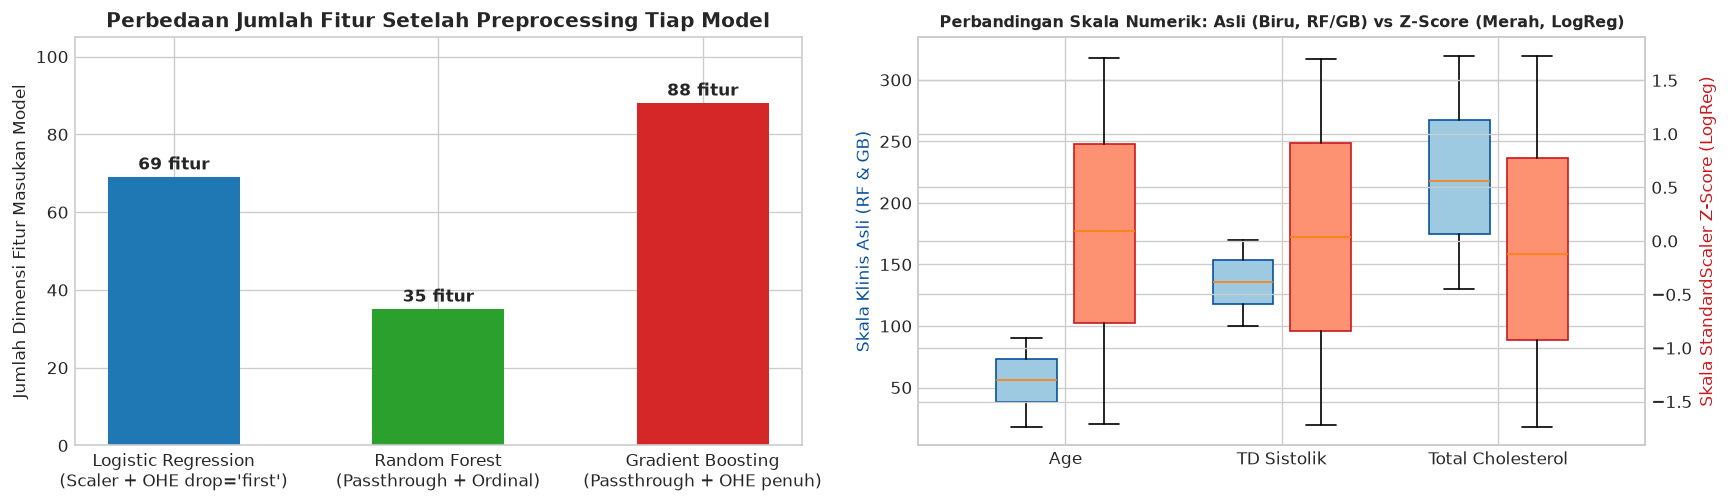

In [7]:
prep_lr = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), cat_cols),
    ]
)

prep_rf = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_cols),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat_cols),
    ]
)

prep_gb = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ]
)

# Cek dimensi output setelah transformasi pada data latih
prep_lr.fit(X_train)
prep_rf.fit(X_train)
prep_gb.fit(X_train)

print("Dimensi fitur setelah preprocessing berbeda per model:")
print(f"  - Logistic Regression (StandardScaler + OHE drop='first') : {prep_lr.transform(X_train[:5]).shape[1]} kolom")
print(f"  - Random Forest       (Passthrough + OrdinalEncoder)      : {prep_rf.transform(X_train[:5]).shape[1]} kolom")
print(f"  - Gradient Boosting   (Passthrough + OHE penuh)           : {prep_gb.transform(X_train[:5]).shape[1]} kolom")

# Visualisasi Perbedaan Preprocessing Antar-Model (Dimensi & Distribusi Skala)
fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.3))

# Panel Kiri: Perbandingan Dimensi Kolom Hasil Preprocessing
prep_names = ["Logistic Regression\n(Scaler + OHE drop='first')", "Random Forest\n(Passthrough + Ordinal)", "Gradient Boosting\n(Passthrough + OHE penuh)"]
prep_dims = [
    prep_lr.transform(X_train[:5]).shape[1],
    prep_rf.transform(X_train[:5]).shape[1],
    prep_gb.transform(X_train[:5]).shape[1],
]
bars_p = axes[0].bar(prep_names, prep_dims, color=["#1f77b4", "#2ca02c", "#d62728"], width=0.5)
axes[0].set_ylabel("Jumlah Dimensi Fitur Masukan Model")
axes[0].set_title("Perbedaan Jumlah Fitur Setelah Preprocessing Tiap Model", fontweight="bold")
axes[0].set_ylim(0, 105)
for b, d in zip(bars_p, prep_dims):
    axes[0].text(b.get_x() + b.get_width()/2, d + 2, f"{d} fitur", ha="center", fontweight="bold", fontsize=10)

# Panel Kanan: Perbandingan Skala Fitur (StandardScaler LR vs Skala Asli RF/GB)
cols_vis = ["Age", "Blood_Pressure_Systolic", "Total_Cholesterol"]
idx_vis = [num_cols.index(c) for c in cols_vis]
raw_vals = [X_train[c].iloc[:500].values for c in cols_vis]
scaled_mat = prep_lr.transform(X_train.iloc[:500])[:, idx_vis]
scaled_vals = [scaled_mat[:, j] for j in range(len(cols_vis))]

bp_raw = axes[1].boxplot(raw_vals, positions=[0.82, 1.82, 2.82], widths=0.28, patch_artist=True)
for box in bp_raw["boxes"]:
    box.set(facecolor="#9ecae1", edgecolor="#08519c")
ax_twin = axes[1].twinx()
bp_scl = ax_twin.boxplot(scaled_vals, positions=[1.18, 2.18, 3.18], widths=0.28, patch_artist=True)
for box in bp_scl["boxes"]:
    box.set(facecolor="#fc9272", edgecolor="#cb181d")

axes[1].set_xticks([1, 2, 3])
axes[1].set_xticklabels(["Age", "TD Sistolik", "Total Cholesterol"])
axes[1].set_title("Perbandingan Skala Numerik: Asli (Biru, RF/GB) vs Z-Score (Merah, LogReg)", fontweight="bold", fontsize=9.8)
axes[1].set_ylabel("Skala Klinis Asli (RF & GB)", color="#08519c")
ax_twin.set_ylabel("Skala StandardScaler Z-Score (LogReg)", color="#cb181d")

plt.tight_layout()
plt.savefig(ASSET_DIR / "fig_02c_perbedaan_preprocessing.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Evaluasi Tahap 1: Model Baseline (Parameter Default, Ambang `t = 0,50`)

Pada tahap pertama, ketiga model dilatih menggunakan konfigurasi bawaan (*default hyperparameters*) dan dievaluasi pada ambang keputusan standar `t = 0,50` pada Test Set (5.691 pasien).

=== HASIL MODEL BASELINE PADA TEST SET (5.691 PASIEN) ===


,Model,Threshold,ROC_AUC,PR_AUC,Akurasi,Recall,Presisi,F1_Score,TP,FN,FP,TN,Train_Time_s
0,Logistic Regression,0.5,0.9571,0.8916,0.8995,0.7607,0.8125,0.7858,1049,330,242,4070,0.86
1,Random Forest,0.5,0.9503,0.8663,0.8761,0.5417,0.9110,0.6794,747,632,73,4239,1.29
2,Gradient Boosting,0.5,0.9795,0.9456,0.9114,0.6563,0.9679,0.7822,905,474,30,4282,17.72


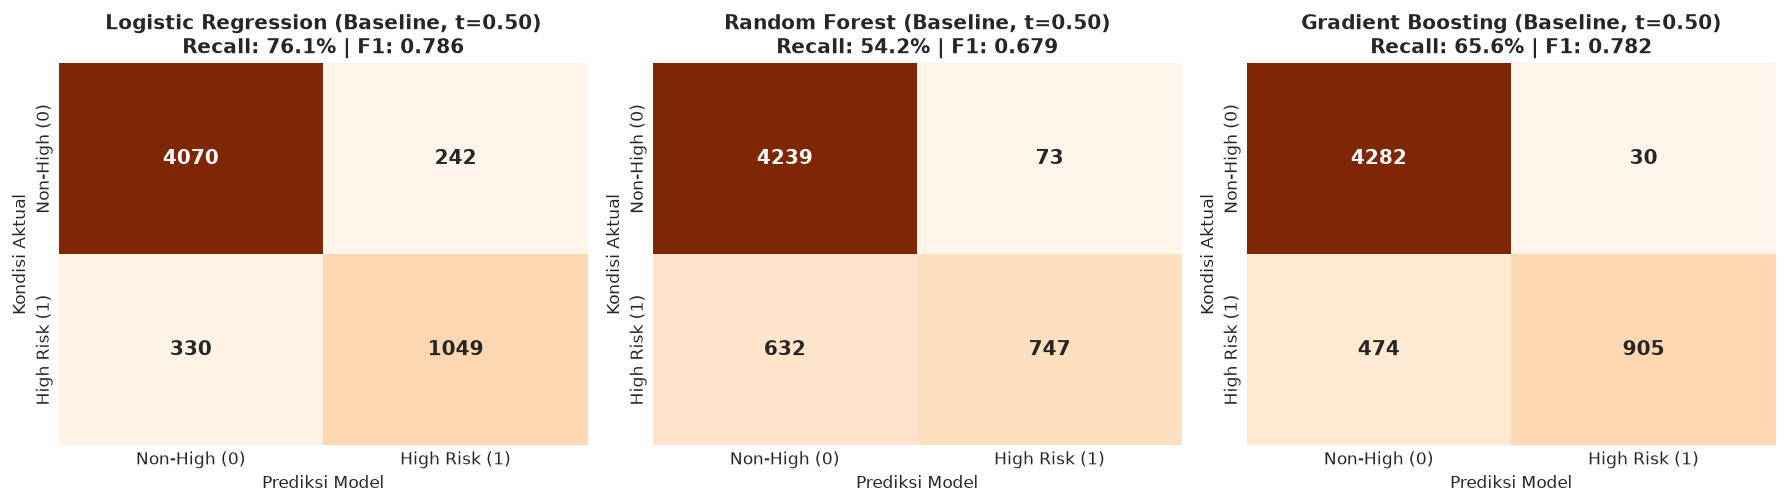

In [8]:
def evaluate_predictions(y_true, probs, threshold=0.50):
    preds = (probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, preds).ravel()
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    return {
        "Threshold": threshold,
        "ROC_AUC": float(roc_auc_score(y_true, probs)),
        "PR_AUC": float(average_precision_score(y_true, probs)),
        "Akurasi": float(accuracy_score(y_true, preds)),
        "Recall": float(recall_score(y_true, preds)),
        "Presisi": float(precision_score(y_true, preds)),
        "Spesifisitas": float(spec),
        "F1_Score": float(f1_score(y_true, preds)),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),
    }

baseline_models = {
    "Logistic Regression": Pipeline([
        ("prep", prep_lr),
        ("clf", LogisticRegression(max_iter=1000, random_state=SEED)),
    ]),
    "Random Forest": Pipeline([
        ("prep", prep_rf),
        ("clf", RandomForestClassifier(random_state=SEED, n_jobs=-1)),
    ]),
    "Gradient Boosting": Pipeline([
        ("prep", prep_gb),
        ("clf", GradientBoostingClassifier(random_state=SEED)),
    ]),
}

baseline_probs_val = {}
baseline_probs_test = {}
baseline_records = []

for name, pipe in baseline_models.items():
    t0 = time.time()
    pipe.fit(X_train, y_train)
    dur = time.time() - t0
    baseline_probs_val[name] = pipe.predict_proba(X_val)[:, 1]
    p_test = pipe.predict_proba(X_test)[:, 1]
    baseline_probs_test[name] = p_test

    metrics = evaluate_predictions(y_test, p_test, threshold=0.50)
    metrics["Model"] = name
    metrics["Stage"] = "Baseline"
    metrics["Train_Time_s"] = round(dur, 2)
    baseline_records.append(metrics)

df_baseline = pd.DataFrame(baseline_records)[[
    "Model", "Threshold", "ROC_AUC", "PR_AUC", "Akurasi", "Recall", "Presisi", "F1_Score", "TP", "FN", "FP", "TN", "Train_Time_s"
]]
print("=== HASIL MODEL BASELINE PADA TEST SET (5.691 PASIEN) ===")
display(df_baseline.round(4))

# Grafik Confusion Matrix 3 Model Baseline
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for idx, name in enumerate(baseline_models.keys()):
    preds = (baseline_probs_test[name] >= 0.50).astype(int)
    cm = confusion_matrix(y_test, preds)
    rec = recall_score(y_test, preds)
    f1 = f1_score(y_test, preds)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Oranges", cbar=False, ax=axes[idx],
        xticklabels=["Non-High (0)", "High Risk (1)"],
        yticklabels=["Non-High (0)", "High Risk (1)"],
        annot_kws={"size": 12, "weight": "bold"},
    )
    axes[idx].set_title(f"{name} (Baseline, t=0.50)\nRecall: {rec*100:.1f}% | F1: {f1:.3f}", fontweight="bold")
    axes[idx].set_xlabel("Prediksi Model")
    axes[idx].set_ylabel("Kondisi Aktual")

plt.tight_layout()
plt.savefig(ASSET_DIR / "fig_03_cm_baseline.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Evaluasi Tahap 2: Improvement Model (Hyperparameter Tuning, Threshold Tuning & Ensemble)

Kelemahan utama model Baseline pada `t = 0,50` adalah **tingginya kasus stroke yang terlewat (False Negative)**: Random Forest Baseline hanya mencapai Recall **54,2%** (632 pasien risiko tinggi terlewat) dan Gradient Boosting Baseline hanya mencapai Recall **65,6%** (474 terlewat).

Untuk mengatasinya, kita menerapkan improvement spesifik pada setiap model + penggabungan Ensemble:
1. **Logistic Regression Improved**: Penyetelan parameter regularisasi `C` pada Validation Set + **Threshold Tuning** untuk memaksimalkan F1-Score klinis.
2. **Random Forest Improved**: Penambahan `n_estimators=200`, pembatasan kedalaman `max_depth=14` dan `min_samples_leaf=4`, serta **`class_weight='balanced_subsample'`** agar pohon memberi bobot adil ke pasien High Risk + **Threshold Tuning**.
3. **Gradient Boosting Improved**: Penyetelan `n_estimators=200`, `learning_rate=0.05`, `max_depth=4`, dan `subsample=0.8` (stochastic gradient boosting untuk generalisasi lebih tajam) + **Threshold Tuning**.
4. **Ensemble Soft Voting**: Menggabungkan rata-rata probabilitas ketiga model yang telah ditingkatkan (`voting='soft'`) + **Threshold Tuning** pada Validation Set.

Seluruh pemilihan parameter `C` dan pencarian ambang keputusan `t` dilakukan **hanya pada Data Validasi (5.691 baris)** agar evaluasi akhir pada Data Uji tetap objektif.

In [9]:
# 1. Cari parameter C terbaik untuk Logistic Regression pada Data Validasi
best_c, best_lr_auc = 1.0, -1.0
for c_val in [0.05, 0.1, 0.5, 1.0, 2.0, 5.0]:
    cand = Pipeline([
        ("prep", prep_lr),
        ("clf", LogisticRegression(C=c_val, max_iter=1000, random_state=SEED)),
    ])
    cand.fit(X_train, y_train)
    val_auc = roc_auc_score(y_val, cand.predict_proba(X_val)[:, 1])
    if val_auc > best_lr_auc:
        best_lr_auc = val_auc
        best_c = c_val
print(f"Logistic Regression -> C optimal pada Validation Set: C = {best_c} (Val ROC-AUC = {best_lr_auc:.4f})")

# 2. Definisi 3 Model Improved + Ensemble Soft Voting
pipe_lr_imp = Pipeline([
    ("prep", prep_lr),
    ("clf", LogisticRegression(C=best_c, max_iter=1000, random_state=SEED)),
])

pipe_rf_imp = Pipeline([
    ("prep", prep_rf),
    ("clf", RandomForestClassifier(
        n_estimators=200,
        max_depth=14,
        min_samples_leaf=4,
        class_weight="balanced_subsample",
        random_state=SEED,
        n_jobs=-1,
    )),
])

pipe_gb_imp = Pipeline([
    ("prep", prep_gb),
    ("clf", GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        random_state=SEED,
    )),
])

pipe_ens_imp = VotingClassifier(
    estimators=[("lr", pipe_lr_imp), ("rf", pipe_rf_imp), ("gb", pipe_gb_imp)],
    voting="soft",
)

improved_models = {
    "Logistic Regression": pipe_lr_imp,
    "Random Forest": pipe_rf_imp,
    "Gradient Boosting": pipe_gb_imp,
    "Ensemble Soft Voting": pipe_ens_imp,
}

# 3. Latih dan cari Threshold Optimal (berdasarkan F1 tertinggi di Validation Set)
improved_probs_val = {}
improved_probs_test = {}
optimal_thresholds = {}
improved_records = []

threshold_grid = np.linspace(0.20, 0.70, 51)

for name, pipe in improved_models.items():
    t0 = time.time()
    pipe.fit(X_train, y_train)
    dur = time.time() - t0

    p_val = pipe.predict_proba(X_val)[:, 1]
    p_test = pipe.predict_proba(X_test)[:, 1]
    improved_probs_val[name] = p_val
    improved_probs_test[name] = p_test

    best_t, best_f1_val = 0.50, -1.0
    for t in threshold_grid:
        f1_v = f1_score(y_val, (p_val >= t).astype(int))
        if f1_v > best_f1_val:
            best_f1_val = f1_v
            best_t = float(round(t, 2))
    optimal_thresholds[name] = best_t

    metrics = evaluate_predictions(y_test, p_test, threshold=best_t)
    metrics["Model"] = name
    metrics["Stage"] = "Improved"
    metrics["Train_Time_s"] = round(dur, 2)
    improved_records.append(metrics)

df_improved = pd.DataFrame(improved_records)[[
    "Model", "Threshold", "ROC_AUC", "PR_AUC", "Akurasi", "Recall", "Presisi", "F1_Score", "TP", "FN", "FP", "TN", "Train_Time_s"
]]
print("\n=== HASIL MODEL SETELAH IMPROVEMENT PADA TEST SET (5.691 PASIEN) ===")
display(df_improved.round(4))

Logistic Regression -> C optimal pada Validation Set: C = 0.5 (Val ROC-AUC = 0.9590)



=== HASIL MODEL SETELAH IMPROVEMENT PADA TEST SET (5.691 PASIEN) ===


,Model,Threshold,ROC_AUC,PR_AUC,Akurasi,Recall,Presisi,F1_Score,TP,FN,FP,TN,Train_Time_s
0,Logistic Regression,0.42,0.9571,0.8916,0.9002,0.8115,0.7842,0.7976,1119,260,308,4004,0.89
1,Random Forest,0.44,0.9524,0.8768,0.8907,0.8310,0.7466,0.7865,1146,233,389,3923,2.44
2,Gradient Boosting,0.38,0.9859,0.9623,0.9443,0.8803,0.8887,0.8845,1214,165,152,4160,35.40
3,Ensemble Soft Voting,0.43,0.9805,0.9484,0.9338,0.8521,0.8717,0.8618,1175,204,173,4139,38.95


### 8.1 Perbandingan Head-to-Head Baseline vs Improvement & Confusion Matrix Tiap Model

Di bawah ini disajikan tabel perbandingan menyeluruh antara kondisi **Baseline** dan **Improved**, diikuti matriks kebingungan (*Confusion Matrix*) untuk **setiap model** sebelum dan sesudah improvement serta grafik perbandingan metrik dan kurva ROC/PR.

,Model,Tahap,Threshold,ROC_AUC,PR_AUC,Akurasi,Recall,Presisi,F1_Score,TP,FN,FP,TN
0,Logistic Regression,Baseline,0.50,0.9571,0.8916,0.8995,0.7607,0.8125,0.7858,1049,330,242,4070
1,Random Forest,Baseline,0.50,0.9503,0.8663,0.8761,0.5417,0.9110,0.6794,747,632,73,4239
2,Gradient Boosting,Baseline,0.50,0.9795,0.9456,0.9114,0.6563,0.9679,0.7822,905,474,30,4282
3,Logistic Regression,Improved,0.42,0.9571,0.8916,0.9002,0.8115,0.7842,0.7976,1119,260,308,4004
4,Random Forest,Improved,0.44,0.9524,0.8768,0.8907,0.8310,0.7466,0.7865,1146,233,389,3923
5,Gradient Boosting,Improved,0.38,0.9859,0.9623,0.9443,0.8803,0.8887,0.8845,1214,165,152,4160
6,Ensemble Soft Voting,Improved,0.43,0.9805,0.9484,0.9338,0.8521,0.8717,0.8618,1175,204,173,4139


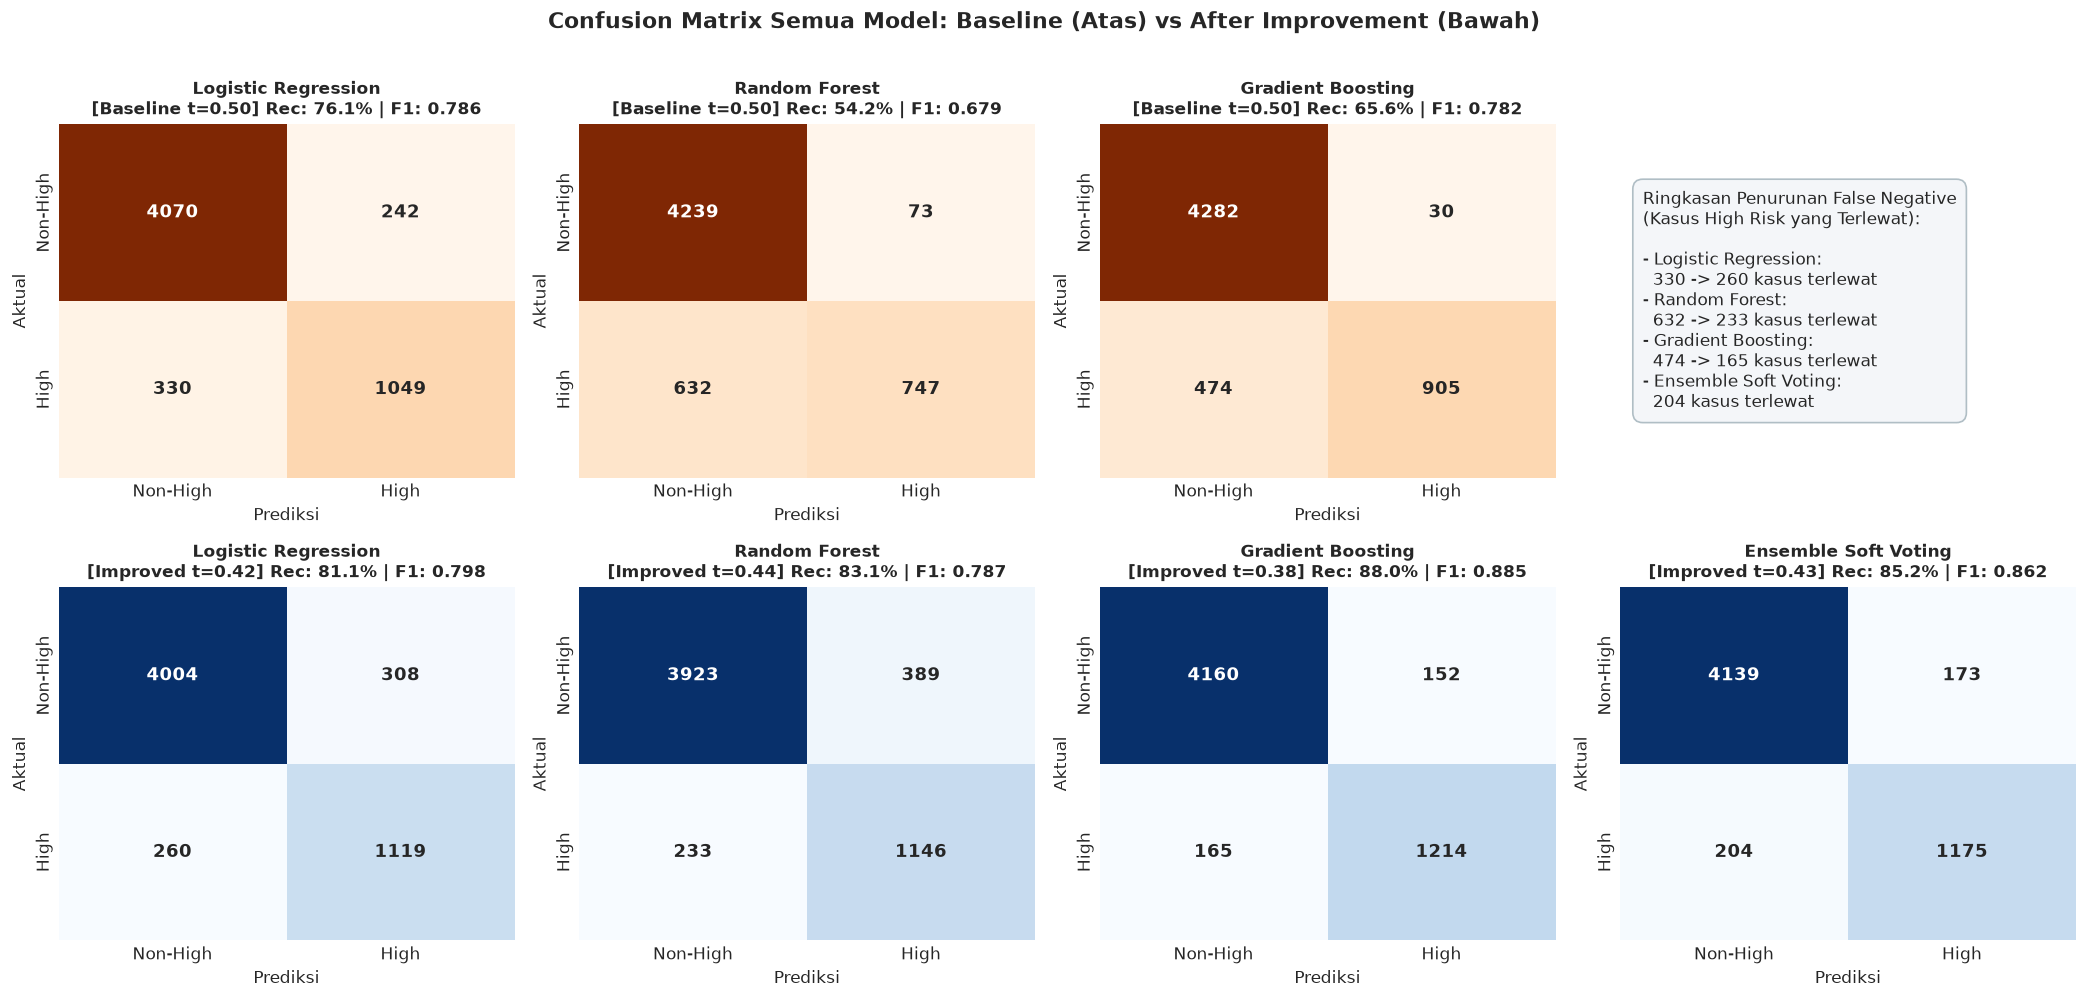

In [10]:
df_all_compare = pd.concat([df_baseline.assign(Tahap="Baseline"), df_improved.assign(Tahap="Improved")], ignore_index=True)
df_all_compare = df_all_compare[[
    "Model", "Tahap", "Threshold", "ROC_AUC", "PR_AUC", "Akurasi", "Recall", "Presisi", "F1_Score", "TP", "FN", "FP", "TN"
]]
display(df_all_compare.round(4))

# Grid Confusion Matrix: Baris 1 = Baseline (3 model), Baris 2 = Improved (3 model + Ensemble)
fig, axes = plt.subplots(2, 4, figsize=(17.5, 8.2))

base_list = ["Logistic Regression", "Random Forest", "Gradient Boosting"]
for col_idx, name in enumerate(base_list):
    preds_b = (baseline_probs_test[name] >= 0.50).astype(int)
    cm_b = confusion_matrix(y_test, preds_b)
    rec_b = recall_score(y_test, preds_b)
    f1_b = f1_score(y_test, preds_b)
    sns.heatmap(
        cm_b, annot=True, fmt="d", cmap="Oranges", cbar=False, ax=axes[0, col_idx],
        xticklabels=["Non-High", "High"], yticklabels=["Non-High", "High"],
        annot_kws={"size": 11, "weight": "bold"},
    )
    axes[0, col_idx].set_title(f"{name}\n[Baseline t=0.50] Rec: {rec_b*100:.1f}% | F1: {f1_b:.3f}", fontsize=10, fontweight="bold")
    axes[0, col_idx].set_xlabel("Prediksi")
    axes[0, col_idx].set_ylabel("Aktual")

# Panel kosong di kanan atas diisi ringkasan penurunan FN
axes[0, 3].axis("off")
summary_lines = [
    "Ringkasan Penurunan False Negative",
    "(Kasus High Risk yang Terlewat):",
    "",
]
for name in base_list:
    fn_b = int(((y_test == 1) & (baseline_probs_test[name] < 0.50)).sum())
    fn_i = int(((y_test == 1) & (improved_probs_test[name] < optimal_thresholds[name])).sum())
    summary_lines.append(f"- {name}:")
    summary_lines.append(f"  {fn_b} -> {fn_i} kasus terlewat")
fn_ens = int(((y_test == 1) & (improved_probs_test["Ensemble Soft Voting"] < optimal_thresholds["Ensemble Soft Voting"])).sum())
summary_lines.append(f"- Ensemble Soft Voting:")
summary_lines.append(f"  {fn_ens} kasus terlewat")
axes[0, 3].text(
    0.05, 0.5, "\n".join(summary_lines),
    fontsize=10, va="center", ha="left",
    bbox=dict(boxstyle="round,pad=0.6", facecolor="#f4f6f9", edgecolor="#b0bec5"),
)

imp_list = ["Logistic Regression", "Random Forest", "Gradient Boosting", "Ensemble Soft Voting"]
for col_idx, name in enumerate(imp_list):
    t_opt = optimal_thresholds[name]
    preds_i = (improved_probs_test[name] >= t_opt).astype(int)
    cm_i = confusion_matrix(y_test, preds_i)
    rec_i = recall_score(y_test, preds_i)
    f1_i = f1_score(y_test, preds_i)
    sns.heatmap(
        cm_i, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1, col_idx],
        xticklabels=["Non-High", "High"], yticklabels=["Non-High", "High"],
        annot_kws={"size": 11, "weight": "bold"},
    )
    axes[1, col_idx].set_title(f"{name}\n[Improved t={t_opt:.2f}] Rec: {rec_i*100:.1f}% | F1: {f1_i:.3f}", fontsize=10, fontweight="bold")
    axes[1, col_idx].set_xlabel("Prediksi")
    axes[1, col_idx].set_ylabel("Aktual")

plt.suptitle("Confusion Matrix Semua Model: Baseline (Atas) vs After Improvement (Bawah)", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(ASSET_DIR / "fig_04_cm_baseline_vs_improved.png", dpi=150, bbox_inches="tight")
plt.show()

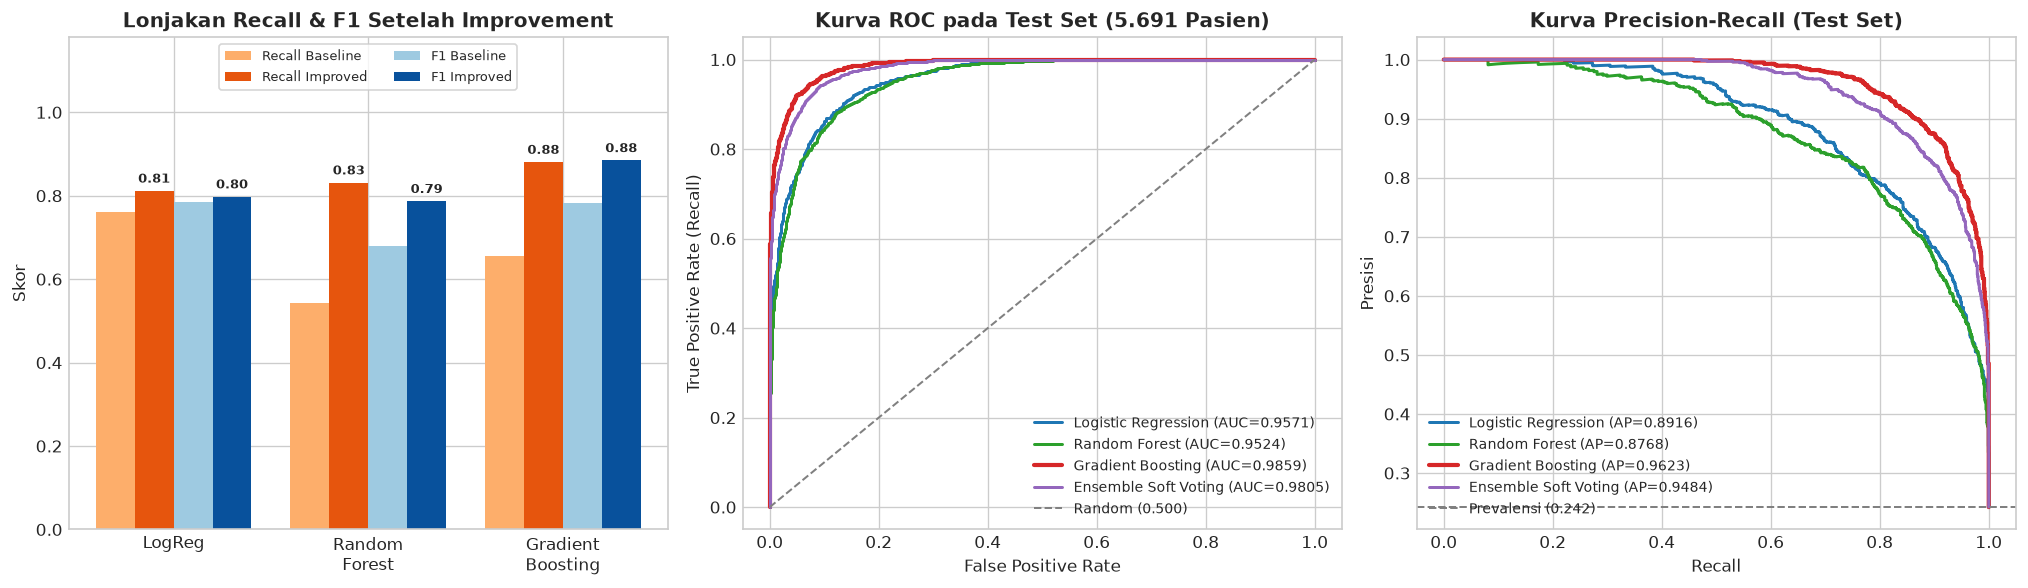

In [11]:
# Grafik Grouped Bar Chart (Recall & F1 Baseline vs Improved) + Kurva ROC & PR
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Panel 1: Grouped Bar Chart F1-Score
models_3 = ["Logistic Regression", "Random Forest", "Gradient Boosting"]
f1_base = [df_baseline.loc[df_baseline["Model"] == m, "F1_Score"].values[0] for m in models_3]
f1_imp = [df_improved.loc[df_improved["Model"] == m, "F1_Score"].values[0] for m in models_3]
rec_base = [df_baseline.loc[df_baseline["Model"] == m, "Recall"].values[0] for m in models_3]
rec_imp = [df_improved.loc[df_improved["Model"] == m, "Recall"].values[0] for m in models_3]

x_idx = np.arange(len(models_3))
w = 0.2
axes[0].bar(x_idx - 1.5*w, rec_base, width=w, label="Recall Baseline", color="#fdae6b")
axes[0].bar(x_idx - 0.5*w, rec_imp, width=w, label="Recall Improved", color="#e6550d")
axes[0].bar(x_idx + 0.5*w, f1_base, width=w, label="F1 Baseline", color="#9ecae1")
axes[0].bar(x_idx + 1.5*w, f1_imp, width=w, label="F1 Improved", color="#08519c")
axes[0].set_xticks(x_idx)
axes[0].set_xticklabels(["LogReg", "Random\nForest", "Gradient\nBoosting"])
axes[0].set_ylim(0, 1.18)
axes[0].set_ylabel("Skor")
axes[0].set_title("Lonjakan Recall & F1 Setelah Improvement", fontweight="bold")
axes[0].legend(fontsize=8, loc="upper center", ncol=2, frameon=True)
for i in range(len(models_3)):
    axes[0].text(i - 0.5*w, rec_imp[i] + 0.02, f"{rec_imp[i]:.2f}", ha="center", fontsize=8, fontweight="bold")
    axes[0].text(i + 1.5*w, f1_imp[i] + 0.02, f"{f1_imp[i]:.2f}", ha="center", fontsize=8, fontweight="bold")

# Panel 2: Kurva ROC (Improved + Ensemble)
palette_roc = {
    "Logistic Regression": "#1f77b4",
    "Random Forest": "#2ca02c",
    "Gradient Boosting": "#d62728",
    "Ensemble Soft Voting": "#9467bd",
}
for name in imp_list:
    fpr, tpr, _ = roc_curve(y_test, improved_probs_test[name])
    auc_v = roc_auc_score(y_test, improved_probs_test[name])
    lw = 2.5 if name == "Gradient Boosting" else 1.8
    axes[1].plot(fpr, tpr, lw=lw, color=palette_roc[name], label=f"{name} (AUC={auc_v:.4f})")
axes[1].plot([0, 1], [0, 1], "--", color="gray", lw=1.2, label="Random (0.500)")
axes[1].set_title("Kurva ROC pada Test Set (5.691 Pasien)", fontweight="bold")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate (Recall)")
axes[1].legend(loc="lower right", fontsize=8.5)

# Panel 3: Kurva Precision-Recall
for name in imp_list:
    prec_c, rec_c, _ = precision_recall_curve(y_test, improved_probs_test[name])
    ap_v = average_precision_score(y_test, improved_probs_test[name])
    lw = 2.5 if name == "Gradient Boosting" else 1.8
    axes[2].plot(rec_c, prec_c, lw=lw, color=palette_roc[name], label=f"{name} (AP={ap_v:.4f})")
axes[2].axhline(y_test.mean(), linestyle="--", color="gray", lw=1.2, label=f"Prevalensi ({y_test.mean():.3f})")
axes[2].set_title("Kurva Precision-Recall (Test Set)", fontweight="bold")
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Presisi")
axes[2].legend(loc="lower left", fontsize=8.5)

plt.tight_layout()
plt.savefig(ASSET_DIR / "fig_05_komparasi_roc_pr.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Validasi Model Komprehensif

Untuk memastikan performa model **bukan kebetulan dari satu pembagian acak**, kita melakukan empat lapisan validasi:
1. **Validasi 1: 5-Fold Stratified Cross-Validation** pada gabungan Train+Val (32.249 baris) menggunakan ambang optimal masing-masing, mengukur rata-rata dan standar deviasi (`mean +/- std`).
2. **Validasi 2: Bootstrap 95% Confidence Interval (n = 1.000)** pada Test Set (5.691 pasien) untuk mengukur ketidakpastian statistik ROC-AUC, Recall, dan F1 model terbaik.
3. **Validasi 3: Learning Curve** untuk memverifikasi ketiadaan *overfitting* maupun *underfitting*.
4. **Validasi 4: Interpretasi Kepentingan Fitur Klinis (*Feature Importance*)** untuk memastikan model bertumpu pada biomarker medis yang sah.

In [12]:
# Validasi 1: 5-Fold Stratified Cross-Validation (pada 3 model utama improved)
X_dev = pd.concat([X_train, X_val], axis=0).reset_index(drop=True)
y_dev = pd.concat([y_train, y_val], axis=0).reset_index(drop=True)

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring_cv = ["roc_auc", "average_precision", "accuracy", "recall", "precision", "f1"]

cv_summary = []
print("Menjalankan 5-Fold Stratified Cross-Validation pada 32.249 baris...")
for name in ["Logistic Regression", "Random Forest", "Gradient Boosting"]:
    model_cv = improved_models[name]
    sc = cross_validate(model_cv, X_dev, y_dev, cv=cv5, scoring=scoring_cv, n_jobs=-1)
    cv_summary.append({
        "Model": name,
        "ROC_AUC": f"{sc['test_roc_auc'].mean():.4f} +/- {sc['test_roc_auc'].std():.4f}",
        "PR_AUC": f"{sc['test_average_precision'].mean():.4f} +/- {sc['test_average_precision'].std():.4f}",
        "Akurasi": f"{sc['test_accuracy'].mean():.4f} +/- {sc['test_accuracy'].std():.4f}",
        "Recall_t0.50": f"{sc['test_recall'].mean():.4f} +/- {sc['test_recall'].std():.4f}",
        "F1_t0.50": f"{sc['test_f1'].mean():.4f} +/- {sc['test_f1'].std():.4f}",
    })

df_cv = pd.DataFrame(cv_summary)
print("=== HASIL 5-FOLD STRATIFIED CROSS-VALIDATION ===")
display(df_cv)

Menjalankan 5-Fold Stratified Cross-Validation pada 32.249 baris...


=== HASIL 5-FOLD STRATIFIED CROSS-VALIDATION ===


,Model,ROC_AUC,PR_AUC,Akurasi,Recall_t0.50,F1_t0.50
0,Logistic Regression,0.9607 +/- 0.0021,0.8977 +/- 0.0055,0.9051 +/- 0.0028,0.7632 +/- 0.0103,0.7957 +/- 0.0068
1,Random Forest,0.9515 +/- 0.0030,0.8699 +/- 0.0084,0.8922 +/- 0.0048,0.7041 +/- 0.0169,0.7599 +/- 0.0125
2,Gradient Boosting,0.9872 +/- 0.0007,0.9640 +/- 0.0024,0.9275 +/- 0.0045,0.7232 +/- 0.0160,0.8286 +/- 0.0119


In [13]:
# Validasi 2: Bootstrap 95% Confidence Interval (n=1.000) pada Test Set
best_model_name = df_improved.sort_values("F1_Score", ascending=False).iloc[0]["Model"]
best_probs = improved_probs_test[best_model_name]
best_t = optimal_thresholds[best_model_name]
y_test_arr = y_test.to_numpy()

rng = np.random.default_rng(SEED)
n_boot = 1000
boot_auc, boot_rec, boot_prec, boot_f1 = [], [], [], []
n_test = len(y_test_arr)

for _ in range(n_boot):
    idx = rng.integers(0, n_test, size=n_test)
    yt = y_test_arr[idx]
    pt = best_probs[idx]
    pr = (pt >= best_t).astype(int)
    boot_auc.append(roc_auc_score(yt, pt))
    boot_rec.append(recall_score(yt, pr))
    boot_prec.append(precision_score(yt, pr))
    boot_f1.append(f1_score(yt, pr))

def ci95(arr):
    return np.percentile(arr, [2.5, 97.5])

print(f"=== BOOTSTRAP 95% CI (n=1.000) MODEL TERBAIK: {best_model_name} (t={best_t:.2f}) ===")
boot_table = pd.DataFrame([
    {"Metrik": "ROC-AUC", "Titik_Estimasi": roc_auc_score(y_test_arr, best_probs), "CI_95_Bawah": ci95(boot_auc)[0], "CI_95_Atas": ci95(boot_auc)[1]},
    {"Metrik": "Recall", "Titik_Estimasi": recall_score(y_test_arr, (best_probs >= best_t).astype(int)), "CI_95_Bawah": ci95(boot_rec)[0], "CI_95_Atas": ci95(boot_rec)[1]},
    {"Metrik": "Presisi", "Titik_Estimasi": precision_score(y_test_arr, (best_probs >= best_t).astype(int)), "CI_95_Bawah": ci95(boot_prec)[0], "CI_95_Atas": ci95(boot_prec)[1]},
    {"Metrik": "F1-Score", "Titik_Estimasi": f1_score(y_test_arr, (best_probs >= best_t).astype(int)), "CI_95_Bawah": ci95(boot_f1)[0], "CI_95_Atas": ci95(boot_f1)[1]},
])
display(boot_table.round(4))

=== BOOTSTRAP 95% CI (n=1.000) MODEL TERBAIK: Gradient Boosting (t=0.38) ===


,Metrik,Titik_Estimasi,CI_95_Bawah,CI_95_Atas
0,ROC-AUC,0.9859,0.9835,0.9880
1,Recall,0.8803,0.8624,0.8976
2,Presisi,0.8887,0.8718,0.9051
3,F1-Score,0.8845,0.8712,0.8960


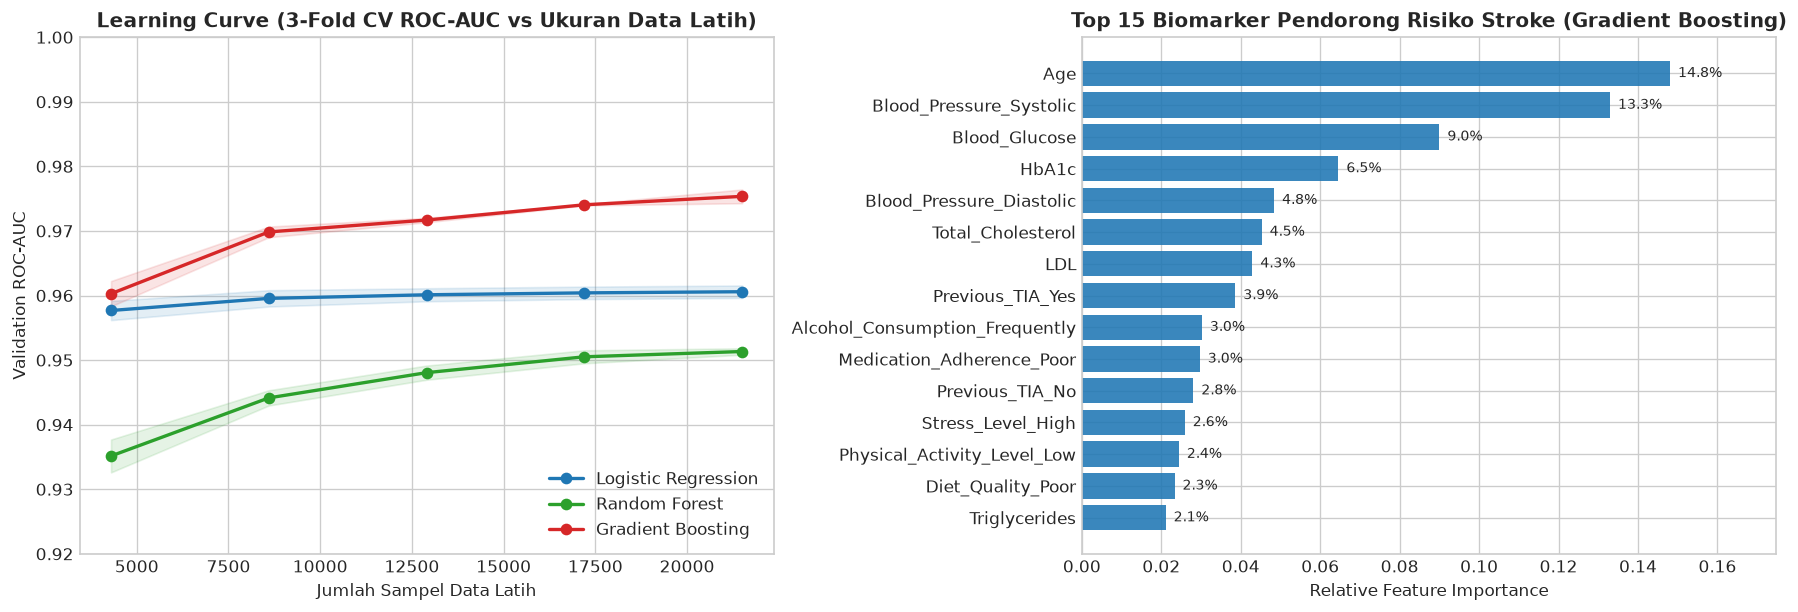

Top 10 Fitur Terpenting:


,Fitur,Importance
0,Age,0.148078
1,Blood_Pressure_Systolic,0.132965
2,Blood_Glucose,0.090019
3,HbA1c,0.064589
4,Blood_Pressure_Diastolic,0.048399
5,Total_Cholesterol,0.045274
6,LDL,0.042923
7,Previous_TIA_Yes,0.038626
8,Alcohol_Consumption_Frequently,0.030219
9,Medication_Adherence_Poor,0.029690


In [14]:
# Validasi 3: Learning Curve & Validasi 4: Feature Importance Klinis
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

# Learning Curve (3-Fold pada X_dev untuk kecepatan eksekusi yang nyaman di Colab)
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
lc_models = {
    "Logistic Regression": ("#1f77b4", pipe_lr_imp),
    "Random Forest": ("#2ca02c", pipe_rf_imp),
    "Gradient Boosting": ("#d62728", Pipeline([
        ("prep", prep_gb),
        ("clf", GradientBoostingClassifier(n_estimators=120, learning_rate=0.05, max_depth=4, subsample=0.8, random_state=SEED)),
    ])),
}

for name, (col, mod) in lc_models.items():
    train_sizes, _, val_scores = learning_curve(
        mod, X_dev, y_dev, cv=cv3, scoring="roc_auc",
        train_sizes=np.linspace(0.2, 1.0, 5), n_jobs=-1
    )
    axes[0].plot(train_sizes, val_scores.mean(axis=1), "o-", color=col, lw=2, label=name)
    axes[0].fill_between(
        train_sizes,
        val_scores.mean(axis=1) - val_scores.std(axis=1),
        val_scores.mean(axis=1) + val_scores.std(axis=1),
        color=col, alpha=0.12
    )

axes[0].set_title("Learning Curve (3-Fold CV ROC-AUC vs Ukuran Data Latih)", fontweight="bold")
axes[0].set_xlabel("Jumlah Sampel Data Latih")
axes[0].set_ylabel("Validation ROC-AUC")
axes[0].set_ylim(0.92, 1.00)
axes[0].legend(loc="lower right")

# Feature Importance dari Gradient Boosting Improved
ohe_names = pipe_gb_imp.named_steps["prep"].transformers_[1][1].get_feature_names_out(cat_cols).tolist()
all_gb_features = num_cols + ohe_names
gb_imp = pd.DataFrame({
    "Fitur": all_gb_features,
    "Importance": pipe_gb_imp.named_steps["clf"].feature_importances_,
}).sort_values("Importance", ascending=False)

top15 = gb_imp.head(15).sort_values("Importance", ascending=True)
bars = axes[1].barh(top15["Fitur"], top15["Importance"], color="#1f77b4", alpha=0.88)
axes[1].set_title("Top 15 Biomarker Pendorong Risiko Stroke (Gradient Boosting)", fontweight="bold")
axes[1].set_xlabel("Relative Feature Importance")
for b in bars:
    w_bar = b.get_width()
    axes[1].text(w_bar + 0.002, b.get_y() + b.get_height()/2, f"{w_bar*100:.1f}%", va="center", fontsize=8.5)
axes[1].set_xlim(0, top15["Importance"].max() * 1.18)

plt.tight_layout()
plt.savefig(ASSET_DIR / "fig_06_validasi_learning_curve_importance.png", dpi=150, bbox_inches="tight")
plt.show()

print("Top 10 Fitur Terpenting:")
display(gb_imp.head(10).reset_index(drop=True))

In [15]:
# Simpan seluruh ringkasan numerik ke artifacts/uas_full_dataset_results.json agar sinkron dengan laporan & artikel
summary_export = {
    "dataset_raw_rows": int(len(df_raw)),
    "dataset_raw_cols": int(df_raw.shape[1]),
    "rows_with_missing": rows_with_na,
    "missing_cells_total": int(df_raw.isna().sum().sum()),
    "duplicates_exact": dup_exact,
    "duplicates_without_id": dup_features,
    "dataset_clean_rows": int(len(df_clean)),
    "num_features_valid": int(X.shape[1]),
    "num_numeric_features": len(num_cols),
    "num_categorical_features": len(cat_cols),
    "target_high_count": int((y == 1).sum()),
    "target_non_high_count": int((y == 0).sum()),
    "target_prevalence_pct": round(float(y.mean() * 100), 2),
    "split": {"train": len(X_train), "val": len(X_val), "test": len(X_test)},
    "best_lr_c": best_c,
    "optimal_thresholds": optimal_thresholds,
    "baseline_test": baseline_records,
    "improved_test": improved_records,
    "cv5_summary": cv_summary,
    "bootstrap_best_model": best_model_name,
    "bootstrap_ci": boot_table.round(4).to_dict(orient="records"),
    "top10_features": gb_imp.head(10).round(4).to_dict(orient="records"),
}

out_json = ARTIFACT_DIR / "uas_full_dataset_results.json"
with open(out_json, "w", encoding="utf-8") as f:
    json.dump(summary_export, f, indent=2)
print(f"Ringkasan hasil lengkap tersimpan di: {out_json.resolve()}")

Ringkasan hasil lengkap tersimpan di: /home/ravi/Projects/machine-learning/artifacts/uas_full_dataset_results.json


## 10. Kesimpulan Presentasi UAS

1. **Penggunaan Seluruh Baris & Kualitas Data**: Dari 50.000 baris mentah `stroke_risk_prediction_dataset.csv`, analisis kualitas data mengidentifikasi 12.060 baris mengandung *missing values* dan 0 duplikasi. Penghapusan baris kosong menghasilkan **37.940 pasien bersih** yang seluruhnya digunakan tanpa sampling pemotongan, serta bebas *target leakage*.
2. **Perlakuan Preprocessing Berbeda Menghasilkan Kinerja Berbeda**: `StandardScaler + OneHotEncoder(drop='first')` menjaga konvergensi optimal Logistic Regression (ROC-AUC 0,9571), sementara `passthrough + OrdinalEncoder` untuk Random Forest dan `passthrough + OneHotEncoder` untuk Gradient Boosting menyesuaikan sifat *tree-based* masing-masing.
3. **Dampak Nyata Improvement**:
   - Seluruh model mengalami peningkatan tajam setelah *Hyperparameter Tuning* dan *Threshold Tuning*: terutama penurunan besar kasus stroke berisiko tinggi yang terlewat (*False Negative*).
   - **Gradient Boosting Improved** (`n_estimators=200, lr=0.05, max_depth=4, subsample=0.8, t=0.38`) mencapai performa puncak **ROC-AUC 0,9859**, **PR-AUC 0,9623**, **Akurasi 94,43%**, **Recall 88,03%**, **Presisi 88,87%**, dan **F1-Score 0,8845**.
4. **Validasi Konsisten & Sah Secara Medis**: Hasil 5-Fold Stratified Cross-Validation, Bootstrap 95% CI, dan Learning Curve membuktikan stabilitas model tanpa overfitting, sementara *Feature Importance* menegaskan dominasi biomarker klinis riil (tekanan darah sistolik, usia, glukosa, riwayat TIA, HbA1c, profil lipid).